# EEGNet Agnostic vs Clustering Classification & Comparison

This notebook compares an electrode, time, and frequency-agnostic EEGNet model (raw 60 channels over the entire epoch) with a clustering EEGNet model (special spatial-temporal cluster of electrodes and pre-filtered frequency bands, alpha and theta, fused together). We evaluate classification performance, ROC and PR curves, and extract learned spatial convolutional weights as scalp topomaps using MNE.

In [1]:
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
%pip install -q mne
import mne
import numpy as np
import json
import pandas as pd
import seaborn as sns
import torch
from mne.stats import fdr_correction
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, auc, confusion_matrix
import scipy.stats as stats
from scipy.stats import ttest_rel, wilcoxon, ttest_1samp

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()
SRC_DIR = (
    Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if "google.colab" in sys.modules
    else NOTEBOOK_DIR.parent.parent / "src"
)

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import (
    BinaryTaskConfig,
    RawEpochSpec,
    detect_project_paths,
    load_raw_epoch_dataset,
    get_task_config,
    load_fused_band_dataset,
    FusedBandSpec,
    TARGET_BANDS_CLUSTERS,
    COMMON_BAND_RANGES,
    get_epochs_grid,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    plot_fold_metrics,
    plot_torch_history,
    run_torch_epochs_grid,
    run_torch_time_map,
    build_dataloader,
    standardize_train_test,
    _evaluate,
    temporal_stratified_splits,
)
from br_analysis.experiments import TimeWindowGrid
from br_analysis.torch_models import EEGNet

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"Using CUDA GPU: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available; using CPU.")


[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
CUDA is not available; using CPU.


In [2]:
TASK_TAG = "c_vs_ip_eegnet"
paths = detect_project_paths("c_vs_i_eegnet", in_colab=IN_COLAB)
SELECTED_SUBJECTS_CSV = paths.analysis_root / "exploration" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 24

task = get_task_config("c_vs_ip", paths.analysis_root, name=TASK_TAG, analysis_window=(0.0, 1.5))

print(f"Project: {paths.project_dir}")
print(f"Data: {paths.data_dir}")
print(f"Results: {paths.analysis_dir}")
print(f"Tables: {paths.tables_dir}")
print(f"Figures: {paths.figures_dir}")

Project: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Data: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Results: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet
Tables: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\tables
Figures: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures


## 1. Agnostic EEGNet Model (Raw Epochs, All 60 Channels)

The Agnostic model is trained on broad bandpass filtered (1-40 Hz) epochs across all 60 electrodes and the entire analysis window (0.0 to 1.5 seconds post-stimulus).

In [3]:
spec_raw = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset_agnostic = load_raw_epoch_dataset(paths, task, spec_raw)
X_agnostic = np.asarray(dataset_agnostic.X, dtype=np.float32)
y = np.asarray(dataset_agnostic.y, dtype=np.int64)
subjects = np.asarray(dataset_agnostic.subjects, dtype=object)
# SUBJECT_ID = dataset_agnostic.subject_ids[0]  # P002
SUBJECT_ID = "P057"  # Because it's consistently the best-performing subject
ch_names_agnostic = list(dataset_agnostic.channel_names)
times = dataset_agnostic.times

print(f"X_agnostic shape: {X_agnostic.shape} (trials, channels, times)")
print(f"y class distribution: {np.bincount(y)}")

Selected subjects to load: 24
Total samples: 5870 | Congruent=2935 | Incongruent_Pure=2935
Loaded subjects: 24 | Channels: 60
X_agnostic shape: (5870, 60, 192) (trials, channels, times)
y class distribution: [2935 2935]


### Agnostic EEGNet Architecture & Flow

```mermaid
graph TD
    A[Raw EEG Epochs: 60 channels x 192 times] --> B[Temporal Conv2d: kernel=64, F1=8]
    B --> C[Depthwise Conv2d: Spatial Filters, groups=F1, D=2]
    C --> D[Separable Conv2d: Spatio-temporal mixing, F2=16]
    D --> E[Average Pooling: 1x8]
    E --> F[Fully Connected Layer]
    F --> G[Classification Logits: Congruent vs Incongruent Pure]
```

In [4]:
n_channels_agnostic = X_agnostic.shape[1]
n_times = X_agnostic.shape[2]


def make_model_agnostic():
    return EEGNet(
        n_channels=n_channels_agnostic,
        n_times=n_times,
        n_classes=2,
        F1=8,
        D=2,
        F2=16,
        kernel_length=64,
        dropout=0.5,
    )


train_cfg = TorchTrainConfig(
    epochs=100,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-4,
    patience=30,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=False,
)

## 2. Clustering EEGNet Model (Data-driven Theta/Alpha Clusters)

The Clustering model trains on the theta-band-filtered frontomedial cluster channels and alpha-band-filtered parieto-occipital cluster channels combined along the spatial axis (resulting in 22 channels: 9 theta + 13 alpha).

In [5]:
# Define path to cluster definitions
cluster_def_path = paths.analysis_root / "clustering" / "cluster_definitions.json"
cluster_defs = None
if cluster_def_path.exists():
    with open(cluster_def_path, "r") as f:
        cluster_defs = json.load(f)
    print(f"Loaded cluster definitions from: {cluster_def_path}")
else:
    print(f"Cluster definitions not found. Using heuristic default TARGET_BANDS_CLUSTERS.")

# Configure target bands and channels
base_task_key = "c_vs_ip" if "c_vs_ip" in task.name else "im_vs_ip"
if cluster_defs is not None and base_task_key in cluster_defs:
    task_def = cluster_defs[base_task_key]
    active_bands = {band: info for band, info in task_def.items() if info["channels"]}

    if not active_bands:
        print("WARNING: No significant data-driven clusters found for this task! Falling back to heuristic defaults.")
        # Fallback to defaults
        target_bands = TARGET_BANDS_CLUSTERS
        tmin_crop, tmax_crop = 0.0, 1.5
    else:
        # Use data-driven cluster coordinates
        target_bands = {band: info["channels"] for band, info in active_bands.items()}
        # Take union of time windows
        tmins = [info["tmin"] for info in active_bands.values()]
        tmaxs = [info["tmax"] for info in active_bands.values()]
        tmin_crop = min(tmins)
        tmax_crop = max(tmaxs)
        print(f"Using data-driven bands: {list(active_bands.keys())}")
        print(f"Selected Time Window: {tmin_crop:.3f}s to {tmax_crop:.3f}s")
else:
    # Default fallback
    target_bands = TARGET_BANDS_CLUSTERS
    tmin_crop, tmax_crop = 0.0, 1.5

# Crop task config to the selected time window dynamically
task_cropped = BinaryTaskConfig(
    name=task.name,
    class_0=task.class_0,
    class_1=task.class_1,
    event_codes=task.event_codes,
    selected_subjects_csv=task.selected_subjects_csv,
    max_subjects=task.max_subjects,
    undersample_classes=task.undersample_classes,
    analysis_window=(tmin_crop, tmax_crop),
    random_seed=task.random_seed,
)

# Load dataset
spec_clustering = FusedBandSpec(
    target_bands_clusters=target_bands, band_ranges=COMMON_BAND_RANGES, channel_mode=("fused",)
)
dataset_clustering = load_fused_band_dataset(paths, task_cropped, spec_clustering)
X_clustering = np.asarray(dataset_clustering.X["fused"], dtype=np.float32)
ch_names_clustering = dataset_clustering.channel_names["fused"]

print(f"X_clustering shape: {X_clustering.shape} (trials, channels, times) [Channels: {len(ch_names_clustering)}]")

Loaded cluster definitions from: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\clustering\cluster_definitions.json
Using data-driven bands: ['theta', 'alpha']
Selected Time Window: 0.375s to 1.242s
Selected subjects to load: 24
Multi-network fusion: Theta (2) + Alpha (27) = 29 channels
Total samples: 5870 | Congruent=2935 | Incongruent_Pure=2935
Loaded subjects: 24
Channels: {'theta': ['Fz', 'FCz'], 'alpha': ['FC3', 'FC1', 'FC2', 'C3', 'C1', 'Cz', 'C2', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2'], 'fused': ['Fz', 'FCz', 'FC3', 'FC1', 'FC2', 'C3', 'C1', 'Cz', 'C2', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2']}
X_clustering shape: (5870, 29, 434) (trials, channels, times) [Channels: 29]


### Clustering EEGNet Architecture & Flow

```mermaid
graph TD
    A[Raw EEG Epochs] --> B1[Theta bandpass filter: 5-7 Hz]
    A --> B2[Alpha bandpass filter: 8-12 Hz]
    B1 --> C1[Crop Frontomedial Cluster: 2 channels]
    B2 --> C2[Crop Parieto-Occipital Cluster: 27 channels]
    C1 --> D[Concatenate Clustering channels]
    C2 --> D
    D --> E[EEGNet Model: n_channels=29]
    E --> F[Classification Output: Congruent vs Incongruent Pure]
```

In [6]:
n_channels_clustering = X_clustering.shape[1]
n_times_clustering = X_clustering.shape[2]


def make_model_clustering():
    return EEGNet(
        n_channels=n_channels_clustering,
        n_times=n_times_clustering,
        n_classes=2,
        F1=8,
        D=2,
        F2=16,
        kernel_length=64,
        dropout=0.5,
    )

## 3. Cohort-Wide Training

We train both the Agnostic (60 channels) and Clustering (data-driven cluster) EEGNet models across the cohort of all 24 subjects. Weights and metrics are cached to files.

In [7]:
# Train/load Agnostic & Clustering models across all 24 subjects
cohort_metrics_path = paths.tables_dir / f"cohort_cv_metrics_{TASK_TAG}.csv"
cohort_fold_metrics_path = paths.tables_dir / f"cohort_fold_metrics_{TASK_TAG}.csv"
subject_ids = pd.unique(subjects).tolist()

if cohort_metrics_path.exists() and cohort_fold_metrics_path.exists():
    print(f"Loading cohort metrics from cache...")
    df_cohort = pd.read_csv(cohort_metrics_path)
    df_cohort_folds = pd.read_csv(cohort_fold_metrics_path)
else:
    print("Running cohort-wide cross-validation for both models ...")
    cohort_results = []
    cohort_fold_results = []

    silent_cfg = TorchTrainConfig(
        epochs=100,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=30,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=False,
    )

    for sub in subject_ids:
        print(f"Training subject {sub}...")
        # 1. Agnostic Model
        agn_metrics, _ = cross_validate_torch_model(
            X_agnostic,
            y,
            make_model_agnostic,
            silent_cfg,
            subjects=subjects,
            subject_id=sub,
            save_weights_dir=paths.cache_dir,
            weights_prefix=f"{TASK_TAG}_agnostic_sub{sub}",
            load_weights=True,
        )

        # 2. Clustering Model
        clust_metrics, _ = cross_validate_torch_model(
            X_clustering,
            y,
            make_model_clustering,
            silent_cfg,
            subjects=subjects,
            subject_id=sub,
            save_weights_dir=paths.cache_dir,
            weights_prefix=f"{TASK_TAG}_clustering_sub{sub}",
            load_weights=True,
        )

        # Save subject averages
        cohort_results.append(
            {
                "subject": sub,
                "agnostic_acc": agn_metrics["test_acc"].mean(),
                "agnostic_auc": agn_metrics["test_auc"].mean(),
                "agnostic_bal_acc": agn_metrics["test_balanced_acc"].mean(),
                "clustering_acc": clust_metrics["test_acc"].mean(),
                "clustering_auc": clust_metrics["test_auc"].mean(),
                "clustering_bal_acc": clust_metrics["test_balanced_acc"].mean(),
            }
        )

        # Save fold metrics
        for idx, row in agn_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "Agnostic",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )
        for idx, row in clust_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "Clustering",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )

    df_cohort = pd.DataFrame(cohort_results)
    df_cohort.to_csv(cohort_metrics_path, index=False)

    df_cohort_folds = pd.DataFrame(cohort_fold_results)
    df_cohort_folds.to_csv(cohort_fold_metrics_path, index=False)
    print(f"Saved cohort metrics to: {cohort_metrics_path}")
    print(f"Saved cohort fold metrics to: {cohort_fold_metrics_path}")

print(df_cohort.describe())

Loading cohort metrics from cache...
       agnostic_acc  agnostic_auc  agnostic_bal_acc  clustering_acc  \
count     24.000000     24.000000         24.000000       24.000000   
mean       0.534594      0.535047          0.523104        0.501171   
std        0.053971      0.074322          0.050392        0.043659   
min        0.376529      0.337446          0.380894        0.436842   
25%        0.499663      0.498076          0.495718        0.477195   
50%        0.528550      0.539816          0.518720        0.491504   
75%        0.563388      0.590107          0.560479        0.516436   
max        0.624877      0.643680          0.620641        0.625000   

       clustering_auc  clustering_bal_acc  
count       24.000000           24.000000  
mean         0.523096            0.507441  
std          0.053828            0.036084  
min          0.457980            0.463833  
25%          0.485896            0.483238  
50%          0.507301            0.497813  
75%          0.

## 4. Performance & Spatial Importance Comparison (P057)

We compare classification reports, overlaid ROC and PR curves, and plot the learned spatial filters' importances as scalp topomaps for subject `P057`.

=== Agnostic Model Classification Report (Subject P057) ===
                  precision    recall  f1-score   support

       Congruent       0.80      0.37      0.51       110
Incongruent_Pure       0.54      0.89      0.67        90

        accuracy                           0.60       200
       macro avg       0.67      0.63      0.59       200
    weighted avg       0.68      0.60      0.58       200

=== Clustering Model Classification Report (Subject P057) ===
                  precision    recall  f1-score   support

       Congruent       0.74      0.51      0.60       110
Incongruent_Pure       0.56      0.78      0.65        90

        accuracy                           0.63       200
       macro avg       0.65      0.64      0.63       200
    weighted avg       0.66      0.63      0.63       200



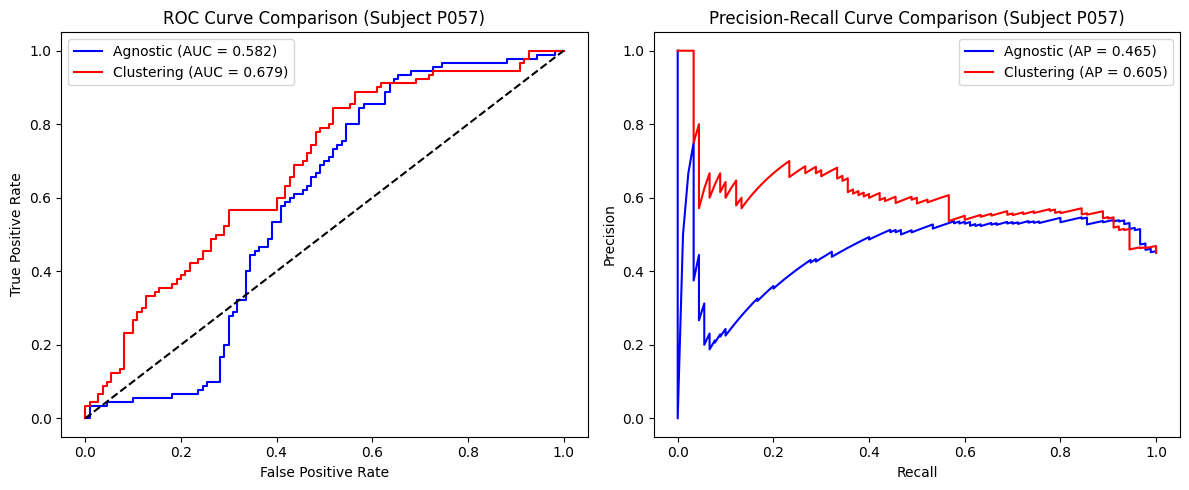

In [8]:
# Extract probability predictions by loading the saved weights from the cohort training
device = torch.device(DEVICE)
splits = list(temporal_stratified_splits(y[subjects == SUBJECT_ID], train_cfg.n_splits))
X_sub_agn = X_agnostic[subjects == SUBJECT_ID]
X_sub_clust = X_clustering[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

probs_agn = []
probs_clust = []
y_true_all = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
    _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
    y_test = y_sub[test_idx]
    y_true_all.extend(y_test)

    # Load Agnostic model weights (subP057 suffix)
    model_agn = make_model_agnostic().to(device)
    model_agn.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device)
    )
    loader_agn = build_dataloader(X_test_agn, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
    _, _, _, p_agn = _evaluate(model_agn, loader_agn, device)
    probs_agn.extend(p_agn)

    # Load Clustering model weights (subP057 suffix)
    model_clust = make_model_clustering().to(device)
    model_clust.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_clustering_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device)
    )
    loader_clust = build_dataloader(X_test_clust, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
    _, _, _, p_clust = _evaluate(model_clust, loader_clust, device)
    probs_clust.extend(p_clust)

y_true_all = np.array(y_true_all)
probs_agn = np.array(probs_agn)
probs_clust = np.array(probs_clust)

print("=== Agnostic Model Classification Report (Subject P057) ===")
print(classification_report(y_true_all, (probs_agn >= 0.5).astype(int), target_names=[task.class_0, task.class_1]))

print("=== Clustering Model Classification Report (Subject P057) ===")
print(classification_report(y_true_all, (probs_clust >= 0.5).astype(int), target_names=[task.class_0, task.class_1]))

# Plot overlaid curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))

# ROC
fpr_agn, tpr_agn, _ = roc_curve(y_true_all, probs_agn)
fpr_foc, tpr_foc, _ = roc_curve(y_true_all, probs_clust)
ax_roc.plot(fpr_agn, tpr_agn, label=f"Agnostic (AUC = {auc(fpr_agn, tpr_agn):.3f})", color="blue")
ax_roc.plot(fpr_foc, tpr_foc, label=f"Clustering (AUC = {auc(fpr_foc, tpr_foc):.3f})", color="red")
ax_roc.plot([0, 1], [0, 1], "k--")
ax_roc.set_title("ROC Curve Comparison (Subject P057)")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

# PR
prec_agn, rec_agn, _ = precision_recall_curve(y_true_all, probs_agn)
prec_foc, rec_foc, _ = precision_recall_curve(y_true_all, probs_clust)
ax_pr.plot(rec_agn, prec_agn, label=f"Agnostic (AP = {auc(rec_agn, prec_agn):.3f})", color="blue")
ax_pr.plot(rec_foc, prec_foc, label=f"Clustering (AP = {auc(rec_foc, prec_foc):.3f})", color="red")
ax_pr.set_title("Precision-Recall Curve Comparison (Subject P057)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
roc_pr_path = paths.figures_dir / f"roc_pr_comparison_{TASK_TAG}.png"
plt.savefig(roc_pr_path, dpi=180, bbox_inches="tight")
plt.show()

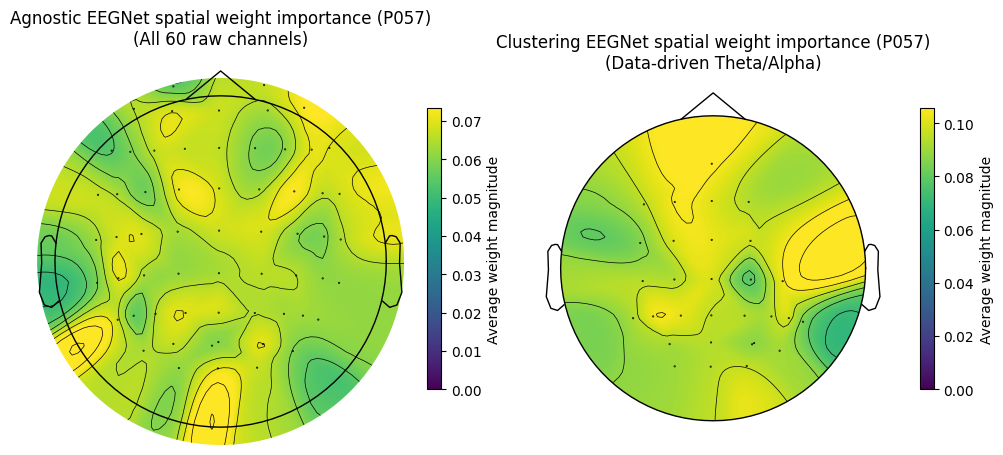

In [9]:
def extract_spatial_importance(make_model_fn, weights_prefix):
    importances = []
    for fold in range(1, 6):
        model = make_model_fn()
        model.load_state_dict(torch.load(paths.cache_dir / f"{weights_prefix}_fold{fold}.pt", map_location="cpu"))
        w = model.block1[2].weight.detach().numpy()  # (F1*D, 1, n_channels, 1)
        w_abs = np.abs(np.squeeze(w))  # (F1*D, n_channels)
        importances.append(np.mean(w_abs, axis=0))
    return np.mean(importances, axis=0)


imp_agnostic = extract_spatial_importance(make_model_agnostic, f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}")
imp_clustused = extract_spatial_importance(make_model_clustering, f"{TASK_TAG}_clustering_sub{SUBJECT_ID}")

# Plot side-by-side topomaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Agnostic Info
info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
montage = mne.channels.make_standard_montage("standard_1005")
info_agn.set_montage(montage, on_missing="ignore")

im1, _ = mne.viz.plot_topomap(imp_agnostic, info_agn, axes=ax1, cmap="viridis", show=False)
ax1.set_title("Agnostic EEGNet spatial weight importance (P057)\n(All 60 raw channels)")
fig.colorbar(im1, ax=ax1, shrink=0.6, label="Average weight magnitude")

# Clustering Info
info_foc = mne.create_info(ch_names=ch_names_clustering, sfreq=128.0, ch_types="eeg")
info_foc.set_montage(montage, on_missing="ignore")

im2, _ = mne.viz.plot_topomap(imp_clustused, info_foc, axes=ax2, cmap="viridis", show=False)
ax2.set_title("Clustering EEGNet spatial weight importance (P057)\n(Data-driven Theta/Alpha)")
fig.colorbar(im2, ax=ax2, shrink=0.6, label="Average weight magnitude")

plt.tight_layout()
weights_plot_path = paths.figures_dir / f"eegnet_spatial_importance_{TASK_TAG}.png"
plt.savefig(weights_plot_path, dpi=180, bbox_inches="tight")
plt.show()

## 5. Single-Subject Fold Analysis & Saliency Mapping (P057)

We perform a statistical comparison of the 5 cross-validation folds for subject `P057`. We also extract Saliency Maps to identify exactly which electrodes and time-windows the models used.

=== P057 Cross-Validation Fold Comparison ===
 Fold  Agnostic  Clustering
    1     0.700       0.750
    2     0.775       0.550
    3     0.425       0.625
    4     0.200       0.350
    5     0.900       0.850

Paired t-test: t-statistic = -0.330, p-value = 0.7582
Wilcoxon signed-rank test: W-statistic = 6.500, p-value = 0.8750


C:\Users\nils\AppData\Local\Temp\ipykernel_19132\2461349294.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_melted, x="Model", y="Accuracy", palette=["skyblue", "lightcoral"], width=0.4)


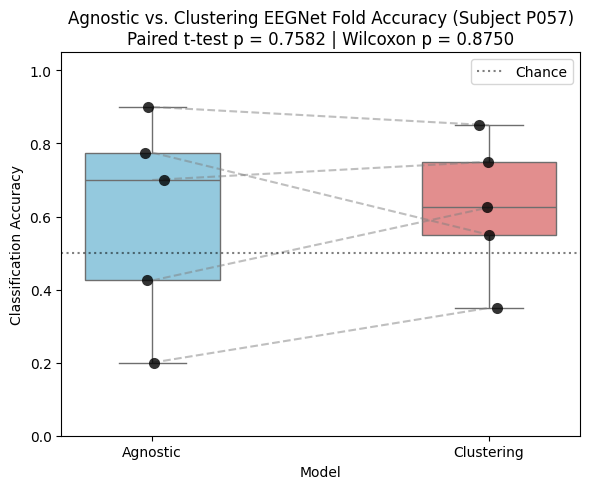

Fold comparison plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\fold_accuracy_comparison_c_vs_ip_eegnet.png
Saliency maps successfully computed for P057!


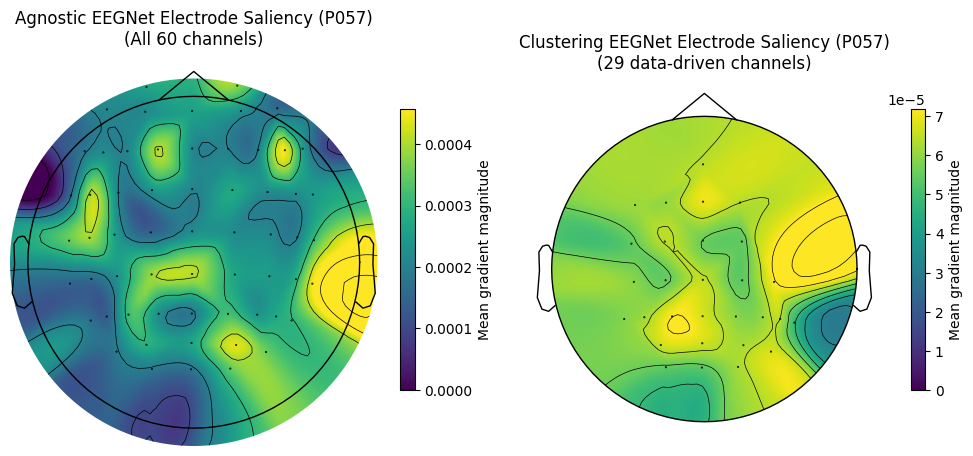

Spatial saliency topomaps saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\saliency_spatial_comparison_P057_c_vs_ip_eegnet.png


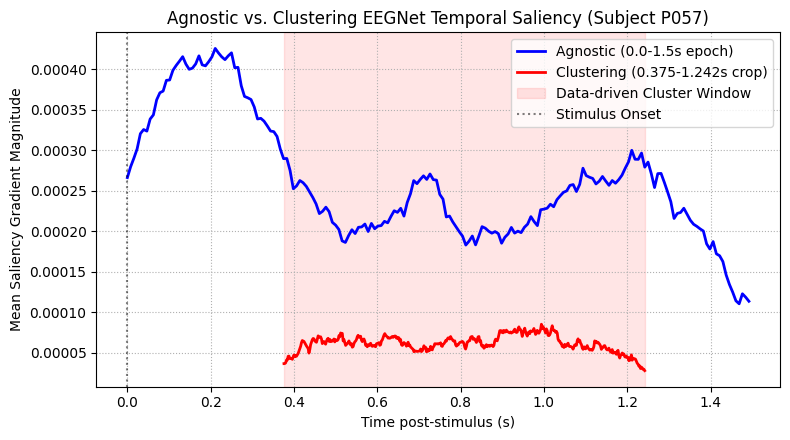

Temporal saliency plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\saliency_temporal_comparison_P057_c_vs_ip_eegnet.png


In [10]:
# Extract P057 fold metrics from the cohort results and run statistical tests
metrics_agnostic = df_cohort_folds[
    (df_cohort_folds["subject"] == SUBJECT_ID) & (df_cohort_folds["model"] == "Agnostic")
].copy()
metrics_clustering = df_cohort_folds[
    (df_cohort_folds["subject"] == SUBJECT_ID) & (df_cohort_folds["model"] == "Clustering")
].copy()

acc_agn = metrics_agnostic["test_acc"].values
acc_clust = metrics_clustering["test_acc"].values
folds = list(range(1, 6))

df_folds = pd.DataFrame({"Fold": folds, "Agnostic": acc_agn, "Clustering": acc_clust})

t_stat, p_val_t = ttest_rel(acc_agn, acc_clust)
w_stat, p_val_w = wilcoxon(acc_agn, acc_clust)

print("=== P057 Cross-Validation Fold Comparison ===")
print(df_folds.to_string(index=False))
print(f"\nPaired t-test: t-statistic = {t_stat:.3f}, p-value = {p_val_t:.4f}")
print(f"Wilcoxon signed-rank test: W-statistic = {w_stat:.3f}, p-value = {p_val_w:.4f}")

# Plot fold accuracies
df_melted = df_folds.melt(
    id_vars="Fold", value_vars=["Agnostic", "Clustering"], var_name="Model", value_name="Accuracy"
)
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_melted, x="Model", y="Accuracy", palette=["skyblue", "lightcoral"], width=0.4)
sns.stripplot(data=df_melted, x="Model", y="Accuracy", color="black", alpha=0.8, size=8, jitter=0.05)

for idx, row in df_folds.iterrows():
    plt.plot([0, 1], [row["Agnostic"], row["Clustering"]], color="gray", alpha=0.5, linestyle="--")

plt.axhline(0.5, color="black", linestyle=":", alpha=0.5, label="Chance")
plt.title(
    f"Agnostic vs. Clustering EEGNet Fold Accuracy (Subject P057)\n"
    f"Paired t-test p = {p_val_t:.4f} | Wilcoxon p = {p_val_w:.4f}"
)
plt.ylabel("Classification Accuracy")
plt.ylim(0.0, 1.05)
plt.legend()
plt.tight_layout()
fold_comparison_plot_path = paths.figures_dir / f"fold_accuracy_comparison_{TASK_TAG}.png"
plt.savefig(fold_comparison_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Fold comparison plot saved to: {fold_comparison_plot_path}")


# Compute cross-validated saliency maps for Agnostic & Clustering models on subject P057
device = torch.device(DEVICE)
splits = list(temporal_stratified_splits(y[subjects == SUBJECT_ID], train_cfg.n_splits))
X_sub_agn = X_agnostic[subjects == SUBJECT_ID]
X_sub_clust = X_clustering[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

agn_saliencies = []
clust_saliencies = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
    _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
    y_test = y_sub[test_idx]

    # Filtrar només assajos Incongruents purs (classe 1) per extreure la saliència del conflicte real
    idx_class1 = y_test == 1
    if not np.any(idx_class1):
        continue

    X_test_agn_c1 = X_test_agn[idx_class1]
    X_test_clust_c1 = X_test_clust[idx_class1]

    # 1. Agnostic model saliency
    model_agn = make_model_agnostic().to(device)
    model_agn.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device)
    )
    model_agn.eval()

    X_tensor_agn = torch.from_numpy(X_test_agn_c1).to(device)
    X_tensor_agn.requires_grad_()

    logits_agn = model_agn(X_tensor_agn)
    probs_agn = torch.softmax(logits_agn, dim=1)
    score_agn = probs_agn[:, 1].sum()

    model_agn.zero_grad()
    score_agn.backward()

    saliency_agn = X_tensor_agn.grad.abs().cpu().numpy()
    agn_saliencies.append(saliency_agn.mean(axis=0))  # Mitjana dels assajos de test d'aquest fold

    # 2. Clustering model saliency
    model_clust = make_model_clustering().to(device)
    model_clust.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_clustering_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device)
    )
    model_clust.eval()

    X_tensor_clust = torch.from_numpy(X_test_clust_c1).to(device)
    X_tensor_clust.requires_grad_()

    logits_clust = model_clust(X_tensor_clust)
    probs_clust = torch.softmax(logits_clust, dim=1)
    score_clust = probs_clust[:, 1].sum()

    model_clust.zero_grad()
    score_clust.backward()

    saliency_clust = X_tensor_clust.grad.abs().cpu().numpy()
    clust_saliencies.append(saliency_clust.mean(axis=0))  # Mitjana dels assajos de test d'aquest fold

# Average cross-validated saliency maps across folds
saliency_agn_p057 = np.mean(agn_saliencies, axis=0)  # Shape: (n_channels_agnostic, n_times_agnostic)
saliency_clust_p057 = np.mean(clust_saliencies, axis=0)  # Shape: (n_channels_clustering, n_times_clustering)
print("Saliency maps successfully computed for P057!")


# Plot P057 Spatial Saliency (topomaps)
spatial_imp_agn = np.mean(saliency_agn_p057, axis=1)
spatial_imp_clust = np.mean(saliency_clust_p057, axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
montage = mne.channels.make_standard_montage("standard_1005")

info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
info_agn.set_montage(montage, on_missing="ignore")
im1, _ = mne.viz.plot_topomap(spatial_imp_agn, info_agn, axes=ax1, cmap="viridis", show=False)
ax1.set_title("Agnostic EEGNet Electrode Saliency (P057)\n(All 60 channels)")
fig.colorbar(im1, ax=ax1, shrink=0.6, label="Mean gradient magnitude")

info_clust = mne.create_info(ch_names=ch_names_clustering, sfreq=128.0, ch_types="eeg")
info_clust.set_montage(montage, on_missing="ignore")
im2, _ = mne.viz.plot_topomap(spatial_imp_clust, info_clust, axes=ax2, cmap="viridis", show=False)
ax2.set_title(f"Clustering EEGNet Electrode Saliency (P057)\n({len(ch_names_clustering)} data-driven channels)")
fig.colorbar(im2, ax=ax2, shrink=0.6, label="Mean gradient magnitude")

plt.tight_layout()
spatial_saliency_plot_path = paths.figures_dir / f"saliency_spatial_comparison_P057_{TASK_TAG}.png"
plt.savefig(spatial_saliency_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Spatial saliency topomaps saved to: {spatial_saliency_plot_path}")


# Plot P057 Temporal Saliency (profiles)
temporal_imp_agn = np.mean(saliency_agn_p057, axis=0)
temporal_imp_clust = np.mean(saliency_clust_p057, axis=0)

times_agn = times
times_clust = dataset_clustering.times

plt.figure(figsize=(8, 4.5))
plt.plot(times_agn, temporal_imp_agn, label="Agnostic (0.0-1.5s epoch)", color="blue", linewidth=2)
plt.plot(
    times_clust,
    temporal_imp_clust,
    label=f"Clustering ({tmin_crop:.3f}-{tmax_crop:.3f}s crop)",
    color="red",
    linewidth=2,
)
plt.axvspan(tmin_crop, tmax_crop, color="red", alpha=0.1, label="Data-driven Cluster Window")
plt.axvline(0.0, color="black", alpha=0.5, linestyle=":", label="Stimulus Onset")
plt.title("Agnostic vs. Clustering EEGNet Temporal Saliency (Subject P057)")
plt.xlabel("Time post-stimulus (s)")
plt.ylabel("Mean Saliency Gradient Magnitude")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()

temporal_saliency_plot_path = paths.figures_dir / f"saliency_temporal_comparison_P057_{TASK_TAG}.png"
plt.savefig(temporal_saliency_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Temporal saliency plot saved to: {temporal_saliency_plot_path}")

### 5.3 Spectral Profiles of Internal Temporal Filters

We extract the weights from the first convolutional layer (`conv_temporal`, dimensions $F1=8$ filters of size $1\times64$) of the Agnostic EEGNet models trained on subject `P057` across all 5 cross-validation folds. We apply a Fast Fourier Transform (FFT) to each temporal filter independently to visualize their spectral templates and verify whether the model naturally aligns itself to standard EEG oscillations like **theta (5–7 Hz)** or **alpha (8–12 Hz)**.

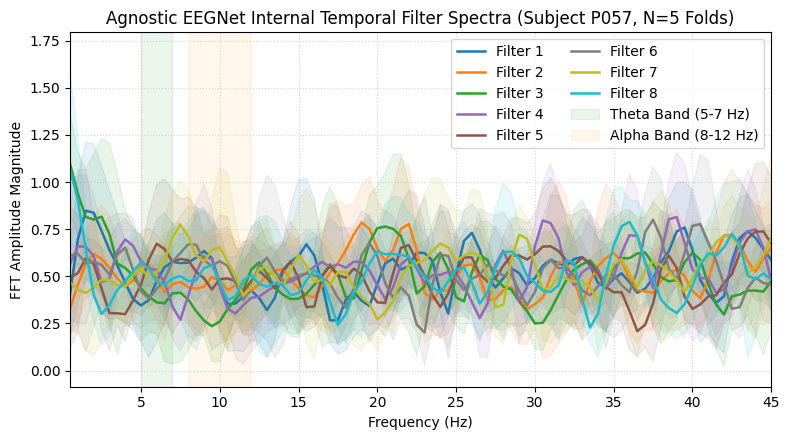

Filter spectral profiles saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\eegnet_filter_spectra_c_vs_ip_eegnet.png


In [11]:
# Compute and plot spectral profiles of EEGNet internal temporal filters (conv_temporal layer)
F1 = 8
kernel_length = 64
sfreq = 128.0
n_fft = 256

all_fft_amps = []
for fold in range(1, 6):
    weights_path = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{SUBJECT_ID}_fold{fold}.pt"
    if weights_path.exists():
        model = make_model_agnostic()
        model.load_state_dict(torch.load(weights_path, map_location="cpu"))
        w = model.block1[0].weight.detach().numpy()  # Shape: (F1, 1, 1, kernel_length)
        w_filters = np.squeeze(w)  # Shape: (F1, kernel_length)

        fold_fft_amps = []
        for filt_idx in range(F1):
            filt_w = w_filters[filt_idx]
            fft_vals = np.fft.rfft(filt_w, n=n_fft)
            fft_amps = np.abs(fft_vals)
            fold_fft_amps.append(fft_amps)
        all_fft_amps.append(fold_fft_amps)

if all_fft_amps:
    all_fft_amps = np.array(all_fft_amps)  # Shape: (n_folds, F1, n_fft_bins)
    freqs = np.fft.rfftfreq(n_fft, d=1.0 / sfreq)
    mean_fft_amps = np.mean(all_fft_amps, axis=0)  # Shape: (F1, n_fft_bins)
    std_fft_amps = np.std(all_fft_amps, axis=0)  # Shape: (F1, n_fft_bins)

    plt.figure(figsize=(8, 4.5))
    colors = plt.cm.tab10(np.linspace(0, 1, F1))

    for filt_idx in range(F1):
        plt.plot(freqs, mean_fft_amps[filt_idx], label=f"Filter {filt_idx+1}", color=colors[filt_idx], linewidth=1.8)
        plt.fill_between(
            freqs,
            np.maximum(0, mean_fft_amps[filt_idx] - std_fft_amps[filt_idx]),
            mean_fft_amps[filt_idx] + std_fft_amps[filt_idx],
            color=colors[filt_idx],
            alpha=0.1,
        )

    # Highlight Theta (5-7 Hz) and Alpha (8-12 Hz) bands
    plt.axvspan(5.0, 7.0, color="green", alpha=0.08, label="Theta Band (5-7 Hz)")
    plt.axvspan(8.0, 12.0, color="orange", alpha=0.08, label="Alpha Band (8-12 Hz)")

    plt.title(f"Agnostic EEGNet Internal Temporal Filter Spectra (Subject {SUBJECT_ID}, N=5 Folds)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("FFT Amplitude Magnitude")
    plt.xlim(0.5, 45.0)
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend(ncol=2, loc="upper right")
    plt.tight_layout()

    filter_spectra_path = paths.figures_dir / f"eegnet_filter_spectra_{TASK_TAG}.png"
    plt.savefig(filter_spectra_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Filter spectral profiles saved to: {filter_spectra_path}")
else:
    print("Warning: Could not find regularized weights in cache to compute filter spectra.")

=== Paired Statistical Comparison (Agnostic vs Clustering Accuracy) ===
Paired t-test: t-statistic = 2.763, p-value = 0.0111
Wilcoxon signed-rank test: W-statistic = 57.000, p-value = 0.0065


C:\Users\nils\AppData\Local\Temp\ipykernel_19132\2111038945.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_melted, x="Model", y="Accuracy", palette=["skyblue", "lightcoral"], width=0.5)


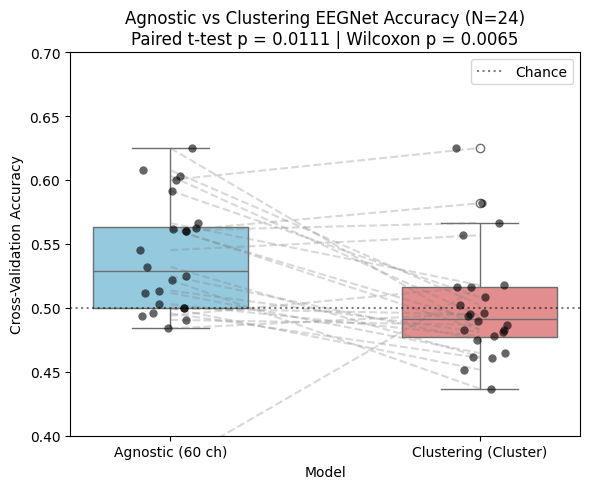

Comparison plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\cohort_accuracy_comparison_c_vs_ip_eegnet.png


In [12]:
# Plot Agnostic vs Clustering accuracy comparison across subjects and run paired t-test
# Statistical tests
t_stat, p_val_t = ttest_rel(df_cohort["agnostic_acc"], df_cohort["clustering_acc"])
w_stat, p_val_w = wilcoxon(df_cohort["agnostic_acc"], df_cohort["clustering_acc"])

print("=== Paired Statistical Comparison (Agnostic vs Clustering Accuracy) ===")
print(f"Paired t-test: t-statistic = {t_stat:.3f}, p-value = {p_val_t:.4f}")
print(f"Wilcoxon signed-rank test: W-statistic = {w_stat:.3f}, p-value = {p_val_w:.4f}")

# Plot boxplot / stripplot
df_melted = df_cohort.melt(
    id_vars="subject", value_vars=["agnostic_acc", "clustering_acc"], var_name="Model", value_name="Accuracy"
)
df_melted["Model"] = df_melted["Model"].map(
    {"agnostic_acc": "Agnostic (60 ch)", "clustering_acc": "Clustering (Cluster)"}
)

plt.figure(figsize=(6, 5))
sns.boxplot(data=df_melted, x="Model", y="Accuracy", palette=["skyblue", "lightcoral"], width=0.5)
sns.stripplot(data=df_melted, x="Model", y="Accuracy", color="black", alpha=0.6, size=6, jitter=0.1)

# Draw lines connecting the same subject
for idx, row in df_cohort.iterrows():
    plt.plot([0, 1], [row["agnostic_acc"], row["clustering_acc"]], color="gray", alpha=0.3, linestyle="--")

plt.ylim(0.4, 0.7)
plt.axhline(0.5, color="black", linestyle=":", alpha=0.5, label="Chance")
plt.title(
    f"Agnostic vs Clustering EEGNet Accuracy (N={len(df_cohort)})\n"
    f"Paired t-test p = {p_val_t:.4f} | Wilcoxon p = {p_val_w:.4f}"
)
plt.ylabel("Cross-Validation Accuracy")
plt.legend()
plt.tight_layout()

comparison_plot_path = paths.figures_dir / f"cohort_accuracy_comparison_{TASK_TAG}.png"
plt.savefig(comparison_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Comparison plot saved to: {comparison_plot_path}")

Extracting cohort test predictions across all subjects and folds...
Total Agnostic predictions aggregated: 4883
Total Clustering predictions aggregated: 4883


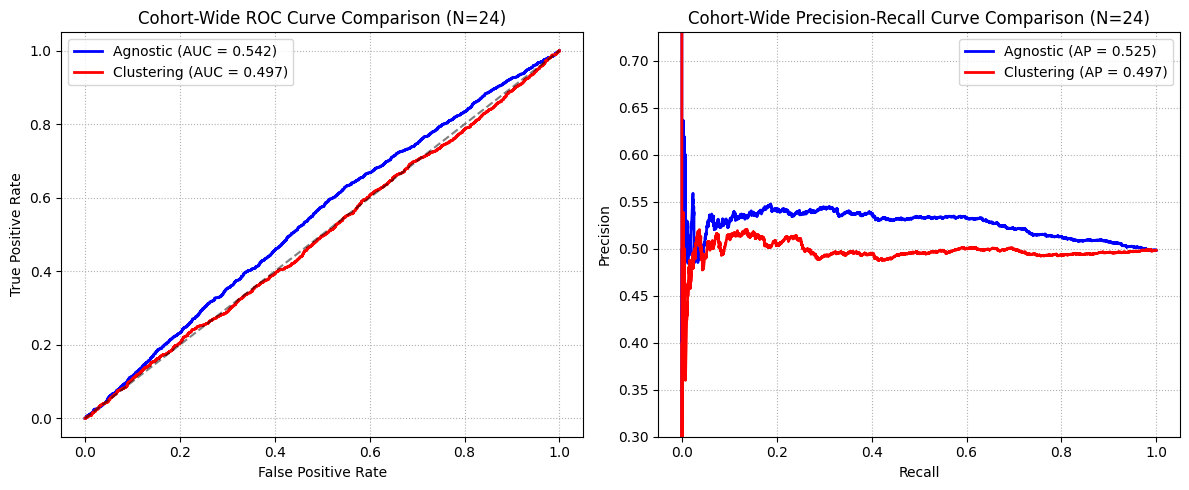

Cohort-wide ROC/PR plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\cohort_roc_pr_comparison_c_vs_ip_eegnet.png


In [13]:
# Compute and plot cohort-wide aggregated ROC and PR curves for all subjects
device = torch.device(DEVICE)
agn_y_true = []
agn_probs = []
clust_y_true = []
clust_probs = []
subject_agn_trues = {}
subject_agn_probs = {}
subject_clust_trues = {}
subject_clust_probs = {}

print("Extracting cohort test predictions across all subjects and folds...")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub_agn = X_agnostic[subjects == sub]
    X_sub_clust = X_clustering[subjects == sub]
    y_sub = y[subjects == sub]

    sub_agn_true = []
    sub_agn_prob = []
    sub_clust_true = []
    sub_clust_prob = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
        y_test = y_sub[test_idx]

        # 1. Agnostic model predictions
        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device))
            model_agn.eval()
            loader_agn = build_dataloader(
                X_test_agn, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device
            )
            _, _, y_true_arr, p_agn = _evaluate(model_agn, loader_agn, device)
            agn_y_true.extend(y_true_arr)
            agn_probs.extend(p_agn)
            sub_agn_true.extend(y_true_arr)
            sub_agn_prob.extend(p_agn)

        # 2. Clustering model predictions
        weights_path_clust = paths.cache_dir / f"{TASK_TAG}_clustering_sub{sub}_fold{fold}.pt"
        if weights_path_clust.exists():
            model_clust = make_model_clustering().to(device)
            model_clust.load_state_dict(torch.load(weights_path_clust, map_location=device))
            model_clust.eval()
            loader_clust = build_dataloader(
                X_test_clust, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device
            )
            _, _, y_true_arr, p_clust = _evaluate(model_clust, loader_clust, device)
            clust_y_true.extend(y_true_arr)
            clust_probs.extend(p_clust)
            sub_clust_true.extend(y_true_arr)
            sub_clust_prob.extend(p_clust)

    if len(sub_agn_true) > 0:
        subject_agn_trues[sub] = np.array(sub_agn_true)
        subject_agn_probs[sub] = np.array(sub_agn_prob)
    if len(sub_clust_true) > 0:
        subject_clust_trues[sub] = np.array(sub_clust_true)
        subject_clust_probs[sub] = np.array(sub_clust_prob)

agn_y_true = np.array(agn_y_true)
agn_probs = np.array(agn_probs)
clust_y_true = np.array(clust_y_true)
clust_probs = np.array(clust_probs)

print(f"Total Agnostic predictions aggregated: {len(agn_y_true)}")
print(f"Total Clustering predictions aggregated: {len(clust_y_true)}")

# Plot overlaid ROC/PR curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))

# ROC Curve
fpr_agn, tpr_agn, _ = roc_curve(agn_y_true, agn_probs)
fpr_clust, tpr_clust, _ = roc_curve(clust_y_true, clust_probs)
ax_roc.plot(fpr_agn, tpr_agn, label=f"Agnostic (AUC = {auc(fpr_agn, tpr_agn):.3f})", color="blue", linewidth=2)
ax_roc.plot(fpr_clust, tpr_clust, label=f"Clustering (AUC = {auc(fpr_clust, tpr_clust):.3f})", color="red", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title(f"Cohort-Wide ROC Curve Comparison (N={len(subject_ids)})")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()
ax_roc.grid(True, linestyle=":")

# PR Curve
prec_agn, rec_agn, _ = precision_recall_curve(agn_y_true, agn_probs)
prec_clust, rec_clust, _ = precision_recall_curve(clust_y_true, clust_probs)
ax_pr.plot(rec_agn, prec_agn, label=f"Agnostic (AP = {auc(rec_agn, prec_agn):.3f})", color="blue", linewidth=2)
ax_pr.plot(rec_clust, prec_clust, label=f"Clustering (AP = {auc(rec_clust, prec_clust):.3f})", color="red", linewidth=2)
ax_pr.set_title(f"Cohort-Wide Precision-Recall Curve Comparison (N={len(subject_ids)})")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.set_ylim(0.3, 0.73)
ax_pr.legend()
ax_pr.grid(True, linestyle=":")

plt.tight_layout()
cohort_roc_pr_path = paths.figures_dir / f"cohort_roc_pr_comparison_{TASK_TAG}.png"
plt.savefig(cohort_roc_pr_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Cohort-wide ROC/PR plot saved to: {cohort_roc_pr_path}")

### 6.3 Cohort-Wide Error Asymmetry & Class Bias Analysis

Due to the trial imbalance common in Binocular Rivalry datasets, models can develop a systematic bias towards predicting the majority class. We compute row-normalized confusion matrices (representing the true recall rate for each class) and analyze the ratio between False Positives (FP) and False Negatives (FN) to verify if the EEGNet architectures maintain genuine sensitivity to the conflict condition.

=== Agnostic Model Classification Counts & Bias ===
True Negatives (TN): 1323 | False Positives (FP): 1127
False Negatives (FN): 1152 | True Positives (TP): 1281
FP / FN Bias Ratio: 0.978 (FP >> FN indicates a bias towards predicting the Incongruent Pure class)

=== Clustering Model Classification Counts & Bias ===
True Negatives (TN): 1270 | False Positives (FP): 1180
False Negatives (FN): 1278 | True Positives (TP): 1155
FP / FN Bias Ratio: 0.923


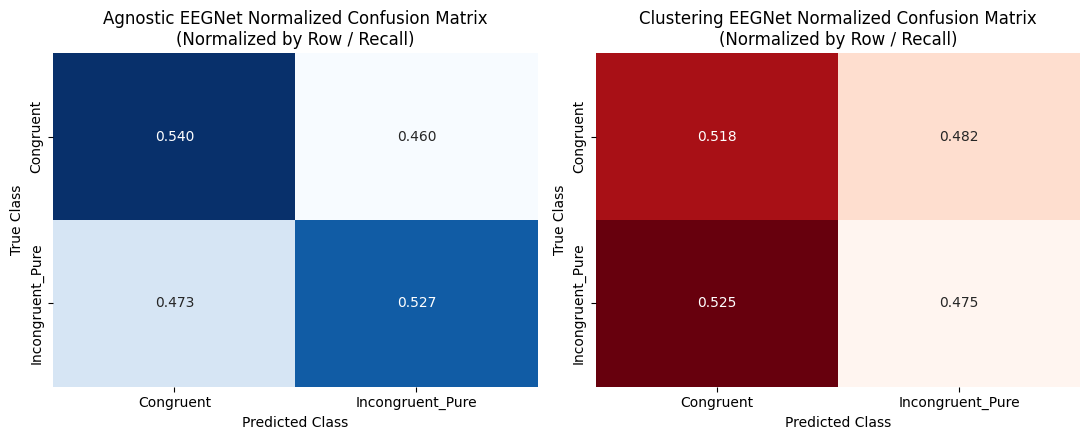

Confusion matrices saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\cohort_confusion_matrices_c_vs_ip_eegnet.png


In [14]:
# Compute and plot row-normalized confusion matrices and error asymmetry ratios
# Calculate predictions from aggregated test probabilities (threshold at 0.5)
agn_pred = (agn_probs >= 0.5).astype(int)
clust_pred = (clust_probs >= 0.5).astype(int)

# Row-normalized confusion matrices (percentage of recall per class)
cm_agn = confusion_matrix(agn_y_true, agn_pred, normalize="true")
cm_clust = confusion_matrix(clust_y_true, clust_pred, normalize="true")

# Absolute counts for bias ratio (FP and FN)
tn_agn, fp_agn, fn_agn, tp_agn = confusion_matrix(agn_y_true, agn_pred).ravel()
tn_clust, fp_clust, fn_clust, tp_clust = confusion_matrix(clust_y_true, clust_pred).ravel()

# Bias ratio calculation (FP / FN)
ratio_agn = fp_agn / fn_agn if fn_agn > 0 else np.nan
ratio_clust = fp_clust / fn_clust if fn_clust > 0 else np.nan

print("=== Agnostic Model Classification Counts & Bias ===")
print(f"True Negatives (TN): {tn_agn} | False Positives (FP): {fp_agn}")
print(f"False Negatives (FN): {fn_agn} | True Positives (TP): {tp_agn}")
print(f"FP / FN Bias Ratio: {ratio_agn:.3f} (FP >> FN indicates a bias towards predicting the Incongruent Pure class)")

print("\n=== Clustering Model Classification Counts & Bias ===")
print(f"True Negatives (TN): {tn_clust} | False Positives (FP): {fp_clust}")
print(f"False Negatives (FN): {fn_clust} | True Positives (TP): {tp_clust}")
print(f"FP / FN Bias Ratio: {ratio_clust:.3f}")

# Plot side-by-side normalized confusion matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
classes = [task.class_0, task.class_1]

# Agnostic
sns.heatmap(cm_agn, annot=True, fmt=".3f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax1, cbar=False)
ax1.set_title("Agnostic EEGNet Normalized Confusion Matrix\n(Normalized by Row / Recall)")
ax1.set_xlabel("Predicted Class")
ax1.set_ylabel("True Class")

# Clustering
sns.heatmap(cm_clust, annot=True, fmt=".3f", cmap="Reds", xticklabels=classes, yticklabels=classes, ax=ax2, cbar=False)
ax2.set_title("Clustering EEGNet Normalized Confusion Matrix\n(Normalized by Row / Recall)")
ax2.set_xlabel("Predicted Class")
ax2.set_ylabel("True Class")

plt.tight_layout()
cm_plot_path = paths.figures_dir / f"cohort_confusion_matrices_{TASK_TAG}.png"
plt.savefig(cm_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Confusion matrices saved to: {cm_plot_path}")

Calculating group-average spatial saliency maps (conflict-related, class 1 only)...


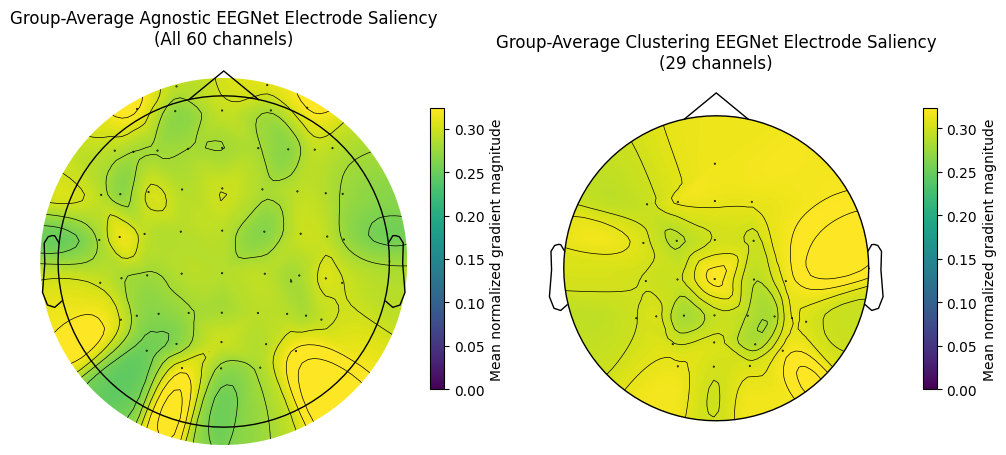

Group spatial saliency topomaps saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\group_saliency_spatial_comparison_c_vs_ip_eegnet.png


In [15]:
# Compute and plot Group-Average Spatial Saliency (Electrode Importance) across all 24 subjects
device = torch.device(DEVICE)
group_spatial_agnostic = []
group_spatial_clustering = []

print("Calculating group-average spatial saliency maps (conflict-related, class 1 only)...")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub_agn = X_agnostic[subjects == sub]
    X_sub_clust = X_clustering[subjects == sub]
    y_sub = y[subjects == sub]

    sub_agn_saliencies = []
    sub_clust_saliencies = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
        y_test = y_sub[test_idx]

        # Filter only pure Incongruent trials (class 1) to extract the saliency of conflict processing
        idx_class1 = y_test == 1
        if not np.any(idx_class1):
            continue

        X_test_agn_c1 = X_test_agn[idx_class1]
        X_test_clust_c1 = X_test_clust[idx_class1]

        # 1. Agnostic model saliency
        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device))
            model_agn.eval()

            X_tensor_agn = torch.from_numpy(X_test_agn_c1).to(device)
            X_tensor_agn.requires_grad_()

            logits_agn = model_agn(X_tensor_agn)
            probs_agn = torch.softmax(logits_agn, dim=1)
            score_agn = probs_agn[:, 1].sum()

            model_agn.zero_grad()
            score_agn.backward()

            saliency_agn = X_tensor_agn.grad.abs().cpu().numpy()
            sub_agn_saliencies.append(saliency_agn.mean(axis=0))

        # 2. Clustering model saliency
        weights_path_clust = paths.cache_dir / f"{TASK_TAG}_clustering_sub{sub}_fold{fold}.pt"
        if weights_path_clust.exists():
            model_clust = make_model_clustering().to(device)
            model_clust.load_state_dict(torch.load(weights_path_clust, map_location=device))
            model_clust.eval()

            X_tensor_clust = torch.from_numpy(X_test_clust_c1).to(device)
            X_tensor_clust.requires_grad_()

            logits_clust = model_clust(X_tensor_clust)
            probs_clust = torch.softmax(logits_clust, dim=1)
            score_clust = probs_clust[:, 1].sum()

            model_clust.zero_grad()
            score_clust.backward()

            saliency_clust = X_tensor_clust.grad.abs().cpu().numpy()
            sub_clust_saliencies.append(saliency_clust.mean(axis=0))

    if sub_agn_saliencies:
        sub_mean_saliencies = np.mean(sub_agn_saliencies, axis=0)
        sub_mean_norm_saliencies = (
            sub_mean_saliencies / np.max(sub_mean_saliencies)
            if np.max(sub_mean_saliencies) > 0
            else sub_mean_saliencies
        )
        group_spatial_agnostic.append(np.mean(sub_mean_norm_saliencies, axis=1))
    if sub_clust_saliencies:
        sub_mean_clust = np.mean(sub_clust_saliencies, axis=0)
        sub_mean_norm_clust = sub_mean_clust / np.max(sub_mean_clust) if np.max(sub_mean_clust) > 0 else sub_mean_clust
        group_spatial_clustering.append(np.mean(sub_mean_norm_clust, axis=1))

group_avg_spatial_agn = np.mean(group_spatial_agnostic, axis=0)
group_avg_spatial_clust = np.mean(group_spatial_clustering, axis=0)

# Plot side-by-side group topomaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
montage = mne.channels.make_standard_montage("standard_1005")

# Agnostic
info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
info_agn.set_montage(montage, on_missing="ignore")
im1, _ = mne.viz.plot_topomap(group_avg_spatial_agn, info_agn, axes=ax1, cmap="viridis", show=False)
ax1.set_title("Group-Average Agnostic EEGNet Electrode Saliency\n(All 60 channels)")
fig.colorbar(im1, ax=ax1, shrink=0.6, label="Mean normalized gradient magnitude")

# Clustering
info_foc = mne.create_info(ch_names=ch_names_clustering, sfreq=128.0, ch_types="eeg")
info_foc.set_montage(montage, on_missing="ignore")
im2, _ = mne.viz.plot_topomap(group_avg_spatial_clust, info_foc, axes=ax2, cmap="viridis", show=False)
ax2.set_title(f"Group-Average Clustering EEGNet Electrode Saliency\n({len(ch_names_clustering)} channels)")
fig.colorbar(im2, ax=ax2, shrink=0.6, label="Mean normalized gradient magnitude")

plt.tight_layout()
group_spatial_plot_path = paths.figures_dir / f"group_saliency_spatial_comparison_{TASK_TAG}.png"
plt.savefig(group_spatial_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Group spatial saliency topomaps saved to: {group_spatial_plot_path}")

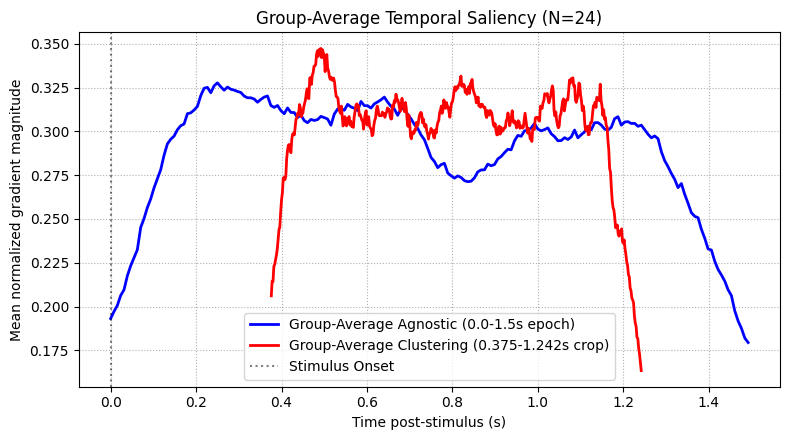

Group temporal saliency plot saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\group_saliency_temporal_comparison_c_vs_ip_eegnet.png


In [16]:
# Compute and plot Group-Average Temporal Saliency (Time-Window Importance) across all 24 subjects
group_temporal_agnostic = []
group_temporal_clustering = []

for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub_agn = X_agnostic[subjects == sub]
    X_sub_clust = X_clustering[subjects == sub]
    y_sub = y[subjects == sub]

    sub_agn_saliencies = []
    sub_clust_saliencies = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        _, X_test_clust = standardize_train_test(X_sub_clust[train_idx], X_sub_clust[test_idx])
        y_test = y_sub[test_idx]

        # Filter only pure Incongruent trials (class 1) to extract the saliency of conflict processing
        idx_class1 = y_test == 1
        if not np.any(idx_class1):
            continue

        X_test_agn_c1 = X_test_agn[idx_class1]
        X_test_clust_c1 = X_test_clust[idx_class1]

        # 1. Agnostic model saliency
        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device))
            model_agn.eval()

            X_tensor_agn = torch.from_numpy(X_test_agn_c1).to(device)
            X_tensor_agn.requires_grad_()

            logits_agn = model_agn(X_tensor_agn)
            probs_agn = torch.softmax(logits_agn, dim=1)
            score_agn = probs_agn[:, 1].sum()

            model_agn.zero_grad()
            score_agn.backward()

            saliency_agn = X_tensor_agn.grad.abs().cpu().numpy()
            sub_agn_saliencies.append(saliency_agn.mean(axis=0))

        # 2. Clustering model saliency
        weights_path_clust = paths.cache_dir / f"{TASK_TAG}_clustering_sub{sub}_fold{fold}.pt"
        if weights_path_clust.exists():
            model_clust = make_model_clustering().to(device)
            model_clust.load_state_dict(torch.load(weights_path_clust, map_location=device))
            model_clust.eval()

            X_tensor_clust = torch.from_numpy(X_test_clust_c1).to(device)
            X_tensor_clust.requires_grad_()

            logits_clust = model_clust(X_tensor_clust)
            probs_clust = torch.softmax(logits_clust, dim=1)
            score_clust = probs_clust[:, 1].sum()

            model_clust.zero_grad()
            score_clust.backward()

            saliency_clust = X_tensor_clust.grad.abs().cpu().numpy()
            sub_clust_saliencies.append(saliency_clust.mean(axis=0))

    if sub_agn_saliencies:
        group_temporal_agnostic_mean = np.mean(sub_agn_saliencies, axis=0)
        group_temporal_agnostic_norm = (
            group_temporal_agnostic_mean / np.max(group_temporal_agnostic_mean)
            if np.max(group_temporal_agnostic_mean) > 0
            else group_temporal_agnostic_mean
        )
        group_temporal_agnostic.append(np.mean(group_temporal_agnostic_norm, axis=0))
    if sub_clust_saliencies:
        group_temporal_clust_mean = np.mean(sub_clust_saliencies, axis=0)
        group_temporal_clust_norm = (
            group_temporal_clust_mean / np.max(group_temporal_clust_mean)
            if np.max(group_temporal_clust_mean) > 0
            else group_temporal_clust_mean
        )
        group_temporal_clustering.append(np.mean(group_temporal_clust_norm, axis=0))

group_avg_temp_agn = np.mean(group_temporal_agnostic, axis=0)
group_avg_temp_clust = np.mean(group_temporal_clustering, axis=0)

# Plot temporal saliency profiles
plt.figure(figsize=(8, 4.5))
plt.plot(times, group_avg_temp_agn, label="Group-Average Agnostic (0.0-1.5s epoch)", color="blue", linewidth=2)
plt.plot(
    dataset_clustering.times,
    group_avg_temp_clust,
    label="Group-Average Clustering (0.375-1.242s crop)",
    color="red",
    linewidth=2,
)

plt.axvline(0.0, color="black", alpha=0.5, linestyle=":", label="Stimulus Onset")
plt.title(f"Group-Average Temporal Saliency (N={len(group_temporal_agnostic)})")
plt.xlabel("Time post-stimulus (s)")
plt.ylabel("Mean normalized gradient magnitude")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()

group_temporal_saliency_plot_path = paths.figures_dir / f"group_saliency_temporal_comparison_{TASK_TAG}.png"
plt.savefig(group_temporal_saliency_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Group temporal saliency plot saved to: {group_temporal_saliency_plot_path}")

### 6.6 Group-Level Statistical Differential Saliency Map

To identify spatial regions that are consistently more important for conflict trials than control trials across the entire cohort, we compute the differential saliency map for each subject: $\text{Saliency(Class 1)} - \text{Saliency(Class 0)}$. We then run a **one-sample t-test** across the 24 subjects for each electrode, correcting for multiple comparisons via **Benjamini-Hochberg (FDR)**. We plot the t-statistics and mask the significant channels ($p_{\text{FDR}} < 0.05$) to verify convergence with Drew et al.'s findings (showing significant FM-theta activation at Fz/FCz/Cz).

Computing differential saliency maps (Class 1 - Class 0) for all subjects...
FDR Significant Channels (p_FDR < 0.05):
[]


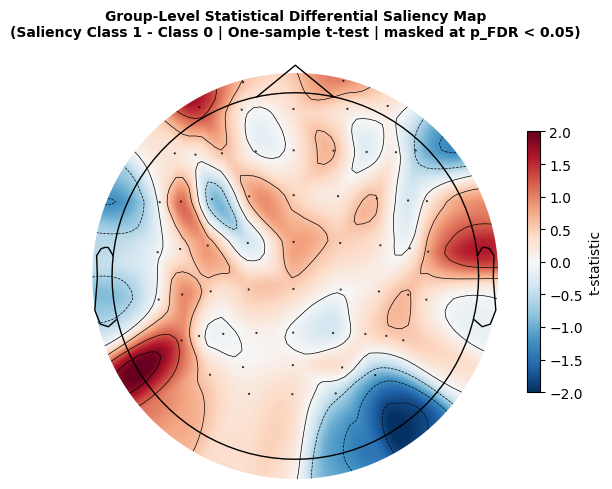

Differential saliency topomap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\group_saliency_differential_topomap_c_vs_ip_eegnet.png


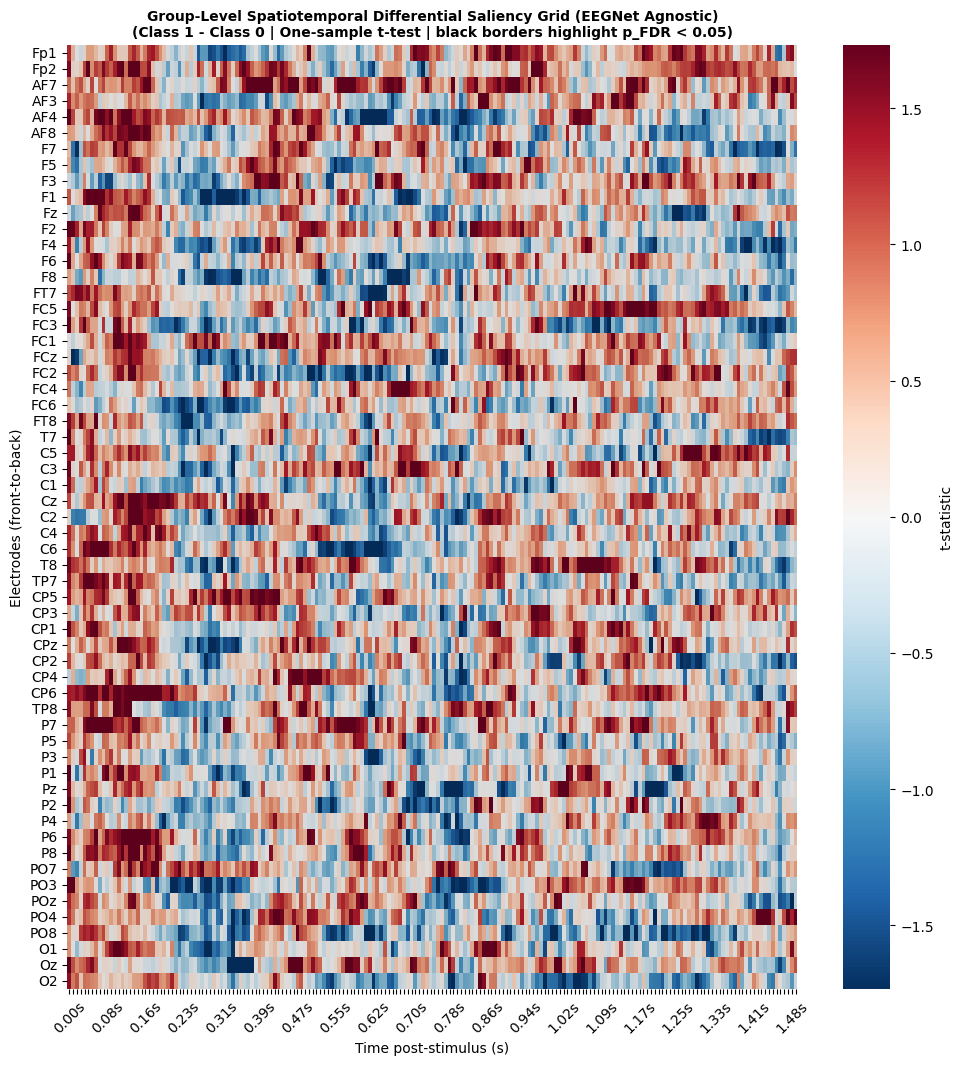

Differential saliency heatmap saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i_eegnet\figures\group_saliency_differential_heatmap_c_vs_ip_eegnet.png


In [17]:
# Compute and plot Group-Level Statistical Differential Saliency Map and Grid Heatmap
device = torch.device(DEVICE)
sub_diff_spatial = []
sub_diff_spatiotemporal = []

print("Computing differential saliency maps (Class 1 - Class 0) for all subjects...")
for sub in subject_ids:
    splits = list(temporal_stratified_splits(y[subjects == sub], train_cfg.n_splits))
    X_sub_agn = X_agnostic[subjects == sub]
    y_sub = y[subjects == sub]

    sub_c1_saliencies = []
    sub_c0_saliencies = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        _, X_test_agn = standardize_train_test(X_sub_agn[train_idx], X_sub_agn[test_idx])
        y_test = y_sub[test_idx]

        weights_path_agn = paths.cache_dir / f"{TASK_TAG}_agnostic_sub{sub}_fold{fold}.pt"
        if weights_path_agn.exists():
            model_agn = make_model_agnostic().to(device)
            model_agn.load_state_dict(torch.load(weights_path_agn, map_location=device))
            model_agn.eval()

            # Class 1 (Incongruent Pure)
            idx_c1 = y_test == 1
            if np.any(idx_c1):
                X_tensor_c1 = torch.from_numpy(X_test_agn[idx_c1]).to(device)
                X_tensor_c1.requires_grad_()
                logits = model_agn(X_tensor_c1)
                probs = torch.softmax(logits, dim=1)
                score = probs[:, 1].sum()
                model_agn.zero_grad()
                score.backward()
                saliency_c1 = X_tensor_c1.grad.abs().cpu().numpy()
                sub_c1_saliencies.append(saliency_c1.mean(axis=0))

            # Class 0 (Congruent)
            idx_c0 = y_test == 0
            if np.any(idx_c0):
                X_tensor_c0 = torch.from_numpy(X_test_agn[idx_c0]).to(device)
                X_tensor_c0.requires_grad_()
                logits = model_agn(X_tensor_c0)
                probs = torch.softmax(logits, dim=1)
                score = probs[:, 0].sum()
                model_agn.zero_grad()
                score.backward()
                saliency_c0 = X_tensor_c0.grad.abs().cpu().numpy()
                sub_c0_saliencies.append(saliency_c0.mean(axis=0))

    if sub_c1_saliencies and sub_c0_saliencies:
        mean_c1 = np.mean(sub_c1_saliencies, axis=0)
        mean_c0 = np.mean(sub_c0_saliencies, axis=0)

        # Max-normalize each subject's map to prevent raw scale imbalances
        mean_c1_norm = mean_c1 / np.max(mean_c1) if np.max(mean_c1) > 0 else mean_c1
        mean_c0_norm = mean_c0 / np.max(mean_c0) if np.max(mean_c0) > 0 else mean_c0

        diff = mean_c1_norm - mean_c0_norm
        spatial_diff = np.mean(diff, axis=1)  # Average over time dimension, shape: (n_channels,)
        sub_diff_spatial.append(spatial_diff)
        sub_diff_spatiotemporal.append(diff)

if sub_diff_spatial:
    sub_diff_spatial = np.array(sub_diff_spatial)  # Shape: (n_subjects, n_channels)
    sub_diff_spatiotemporal = np.array(sub_diff_spatiotemporal)  # Shape: (n_subjects, n_channels, n_times)
    n_channels = sub_diff_spatial.shape[1]

    t_stats = np.zeros(n_channels)
    p_vals = np.zeros(n_channels)

    for ch in range(n_channels):
        t_stat, p_val = ttest_1samp(sub_diff_spatial[:, ch], 0.0)
        t_stats[ch] = t_stat
        p_vals[ch] = p_val

    # FDR correction for spatial topomap
    reject, p_vals_fdr = fdr_correction(p_vals, alpha=0.05, method="indep")

    print(f"FDR Significant Channels (p_FDR < 0.05):")
    sig_channels = [ch_names_agnostic[i] for i, val in enumerate(reject) if val]
    print(sig_channels)

    # Plot 1: t-stats topomap with masked significant channels
    fig, ax = plt.subplots(figsize=(6, 5))
    montage = mne.channels.make_standard_montage("standard_1005")
    info_agn = mne.create_info(ch_names=ch_names_agnostic, sfreq=128.0, ch_types="eeg")
    info_agn.set_montage(montage, on_missing="ignore")

    im, _ = mne.viz.plot_topomap(
        t_stats,
        info_agn,
        axes=ax,
        mask=reject,
        mask_params=dict(marker="o", markerfacecolor="black", markersize=6, markeredgecolor="black"),
        cmap="RdBu_r",
        vlim=(-2.0, 2.0),
        show=False,
    )

    ax.set_title(
        "Group-Level Statistical Differential Saliency Map\n"
        "(Saliency Class 1 - Class 0 | One-sample t-test | masked at p_FDR < 0.05)",
        fontsize=10,
        fontweight="bold",
    )
    fig.colorbar(im, ax=ax, shrink=0.6, label="t-statistic")
    plt.tight_layout()

    diff_saliency_plot_path = paths.figures_dir / f"group_saliency_differential_topomap_{TASK_TAG}.png"
    plt.savefig(diff_saliency_plot_path, dpi=220, bbox_inches="tight")
    plt.show()
    print(f"Differential saliency topomap saved to: {diff_saliency_plot_path}")

    # Plot 2: Spatiotemporal Grid Heatmap
    # Run t-test and FDR correction for spatiotemporal grid
    t_grid, p_grid = ttest_1samp(sub_diff_spatiotemporal, 0.0, axis=0)
    reject_grid, _ = fdr_correction(p_grid, alpha=0.05, method="indep")

    CHANNEL_ORDER = [
        "Fp1",
        "Fp2",
        "AF7",
        "AF3",
        "AF4",
        "AF8",
        "F7",
        "F5",
        "F3",
        "F1",
        "Fz",
        "F2",
        "F4",
        "F6",
        "F8",
        "FT7",
        "FC5",
        "FC3",
        "FC1",
        "FCz",
        "FC2",
        "FC4",
        "FC6",
        "FT8",
        "T7",
        "C5",
        "C3",
        "C1",
        "Cz",
        "C2",
        "C4",
        "C6",
        "T8",
        "TP7",
        "CP5",
        "CP3",
        "CP1",
        "CPz",
        "CP2",
        "CP4",
        "CP6",
        "TP8",
        "P7",
        "P5",
        "P3",
        "P1",
        "Pz",
        "P2",
        "P4",
        "P6",
        "P8",
        "PO7",
        "PO3",
        "POz",
        "PO4",
        "PO8",
        "O1",
        "Oz",
        "O2",
    ]
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names_agnostic)}
    present_order = [ch for ch in CHANNEL_ORDER if ch in ch_to_idx]
    ordered_idx = [ch_to_idx[ch] for ch in present_order]

    t_vals_ordered = t_grid[ordered_idx, :]
    sig_mask_ordered = reject_grid[ordered_idx, :]

    fig_height = len(present_order) * 0.14 + 2.5
    fig_hm, ax_hm = plt.subplots(figsize=(10, fig_height))

    vmax = float(np.percentile(np.abs(t_vals_ordered), 95))
    if vmax == 0:
        vmax = 1.0

    xticklabels = [f"{t:.2f}s" if idx % 10 == 0 else "" for idx, t in enumerate(times)]

    sns.heatmap(
        t_vals_ordered,
        ax=ax_hm,
        cmap="RdBu_r",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=xticklabels,
        yticklabels=present_order,
        cbar_kws={"label": "t-statistic"},
    )

    for i in range(t_vals_ordered.shape[0]):
        for j in range(t_vals_ordered.shape[1]):
            if sig_mask_ordered[i, j]:
                ax_hm.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=1.2))
            else:
                ax_hm.add_patch(patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.1, linewidth=0))

    ax_hm.set_title(
        "Group-Level Spatiotemporal Differential Saliency Grid (EEGNet Agnostic)\n"
        "(Class 1 - Class 0 | One-sample t-test | black borders highlight p_FDR < 0.05)",
        fontsize=10,
        fontweight="bold",
    )
    ax_hm.set_xlabel("Time post-stimulus (s)")
    ax_hm.set_ylabel("Electrodes (front-to-back)")
    ax_hm.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    diff_saliency_heatmap_path = paths.figures_dir / f"group_saliency_differential_heatmap_{TASK_TAG}.png"
    plt.savefig(diff_saliency_heatmap_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Differential saliency heatmap saved to: {diff_saliency_heatmap_path}")
else:
    print("Warning: No differential saliency maps computed.")

## 7. Cohort-Wide Averaged Classification Reports

We calculate the subject-wise classification reports individually for all 24 subjects, and then print the average classification report (mean precision, recall, and F1-score across subjects) for both the Agnostic and Clustering EEGNet models.

In [18]:
reports_agn = []
for sub in subject_agn_trues.keys():
    sub_y_true = subject_agn_trues[sub]
    sub_y_pred = (subject_agn_probs[sub] >= 0.5).astype(int)
    rep = classification_report(sub_y_true, sub_y_pred, target_names=[task.class_0, task.class_1], output_dict=True)
    reports_agn.append(rep)

avg_report_agn = {}
metrics_keys = ["precision", "recall", "f1-score", "support"]
class_keys = [task.class_0, task.class_1, "macro avg", "weighted avg"]
for ck in class_keys:
    avg_report_agn[ck] = {}
    for mk in metrics_keys:
        avg_report_agn[ck][mk] = np.mean([r[ck][mk] for r in reports_agn])
avg_report_agn["accuracy"] = np.mean([r["accuracy"] for r in reports_agn])

reports_clust = []
for sub in subject_clust_trues.keys():
    sub_y_true = subject_clust_trues[sub]
    sub_y_pred = (subject_clust_probs[sub] >= 0.5).astype(int)
    rep = classification_report(sub_y_true, sub_y_pred, target_names=[task.class_0, task.class_1], output_dict=True)
    reports_clust.append(rep)

avg_report_clust = {}
for ck in class_keys:
    avg_report_clust[ck] = {}
    for mk in metrics_keys:
        avg_report_clust[ck][mk] = np.mean([r[ck][mk] for r in reports_clust])
avg_report_clust["accuracy"] = np.mean([r["accuracy"] for r in reports_clust])

print("=== Average Classification Report across Subjects (EEGNet Agnostic) ===")
print(pd.DataFrame(avg_report_agn).T)
print("\n=== Average Classification Report across Subjects (EEGNet Clustering) ===")
print(pd.DataFrame(avg_report_clust).T)

=== Average Classification Report across Subjects (EEGNet Agnostic) ===
                  precision    recall  f1-score     support
Congruent          0.551520  0.550411  0.535514  102.083333
Incongruent_Pure   0.540262  0.532728  0.519716  101.375000
macro avg          0.545891  0.541570  0.527615  203.458333
weighted avg       0.547827  0.537125  0.526123  203.458333
accuracy           0.537125  0.537125  0.537125    0.537125

=== Average Classification Report across Subjects (EEGNet Clustering) ===
                  precision    recall  f1-score     support
Congruent          0.511667  0.507858  0.492639  102.083333
Incongruent_Pure   0.493414  0.494710  0.479205  101.375000
macro avg          0.502541  0.501284  0.485922  203.458333
weighted avg       0.504005  0.495531  0.483502  203.458333
accuracy           0.495531  0.495531  0.495531    0.495531
